# Paisaje espacial real de Oslo — Proyecto 2, parte 1

## 1. Objetivo y fuentes
Construir una primera representación reproducible de parques y zonas libres de abejas, calcular geometría métrica y producir una tabla inicial de parches. Se usan exclusivamente los tres servicios indicados en `data/project2/sources_spatial.md`:

1. [Parques / Greenspace](https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0): Feature Layer de parques y áreas verdes; no se presupone que todos los objetos sean parques del mismo tipo.
2. [Zonas libres de abejas / Honning_Oslobyg](https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Honning_Oslobyg/FeatureServer/0): polígonos de restricción según la fuente documentada.
3. [Aptitud / Egnethet_for_pollinerende_insekter](https://tiles.arcgis.com/tiles/PHc9pAOcTcVH6T4R/arcgis/rest/services/Egnethet_for_pollinerende_insekter/MapServer): se inspeccionan capacidades y metadatos; no se extraen valores de colores.

No se asignan colmenas, recursos florales, polen, néctar ni aptitudes inferidas. No se vinculan traps de Dryad con coordenadas inventadas. Las capas no prueban que las restricciones estén vigentes en una fecha histórica: la regla siguiente es una decisión inicial de modelado basada en la capa suministrada, pendiente de validar su interpretación y vigencia con la autoridad responsable.

## 2. Entorno, rutas y reproducibilidad
Dependencias: GeoPandas, pandas, requests, matplotlib, Shapely y pyproj, declaradas en `requirements.txt`. Se busca la raíz del repositorio desde el directorio actual hacia sus padres; no hay rutas absolutas.

La primera ejecución requiere Internet. Se guardan instantáneas GeoJSON, metadatos, consultas, conteos, fecha UTC y huellas SHA-256 en `data/project2/raw/oslo/gis/`. Por defecto se reutilizan esas instantáneas **de forma explícita**, verificando integridad y URL; `REFRESH_SOURCES = True` fuerza una nueva consulta a las mismas fuentes. No se cambia de proveedor ni se recurre silenciosamente a una caché si falla una actualización. Así las ejecuciones posteriores pueden reproducir la misma geografía sin red.

In [1]:
%matplotlib inline
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import sys

import geopandas as gpd
import pandas as pd
import requests
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
import shapely
from shapely import make_valid
from shapely.ops import unary_union
from pyproj import CRS
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/project2/sources_spatial.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Ejecute desde el repositorio o un subdirectorio: falta sources_spatial.md.")
RAW = ROOT / "data/project2/raw/oslo/gis"
OUT = ROOT / "data/project2/processed"
RAW.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
REFRESH_SOURCES = False
METRIC_CRS = CRS.from_epsg(25833)  # ETRS89 / UTM zone 33N, metros.
BASE = "https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services"
SOURCES = {"greenspace": BASE + "/Greenspace/FeatureServer/0",
           "bee_free_zones": BASE + "/Honning_Oslobyg/FeatureServer/0"}
SUITABILITY_URL = "https://tiles.arcgis.com/tiles/PHc9pAOcTcVH6T4R/arcgis/rest/services/Egnethet_for_pollinerende_insekter/MapServer"
session = requests.Session()
retry = Retry(total=2, backoff_factor=.5, status_forcelist=[429, 500, 502, 503, 504], allowed_methods=["GET"])
session.mount("https://", HTTPAdapter(max_retries=retry))
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 13})
pd.set_option("display.max_columns", 22)
pd.set_option("display.max_colwidth", 100)
print(f"Python {sys.version.split()[0]} | GeoPandas {gpd.__version__} | pandas {pd.__version__}")
print(f"Shapely {shapely.__version__} | requests {requests.__version__} | matplotlib {matplotlib.__version__}")
print("CRS analítico:", METRIC_CRS.name, "| unidades:", METRIC_CRS.axis_info[0].unit_name)

Python 3.10.11 | GeoPandas 1.1.4 | pandas 2.3.3
Shapely 2.1.2 | requests 2.34.2 | matplotlib 3.10.9
CRS analítico: ETRS89 / UTM zone 33N | unidades: metre


## 3. Descarga REST completa y control de integridad
Se solicitan los IDs de todos los objetos y se descargan lotes por ID, evitando truncar por `maxRecordCount`. Cada lote se comprueba contra los IDs solicitados; al finalizar se vuelven a consultar IDs y conteo. Si cambió la capa durante la consulta, se detiene la ejecución con un error claro. Los GeoJSON se solicitan en EPSG:4326 y sin Z/M porque este modelo es bidimensional. Se conservan todos los atributos originales.

Los errores HTTP, de conexión, JSON y ArcGIS se distinguen de una respuesta válida. Ante un fallo indispensable no se fabrican datos ni se exportan resultados parciales.

In [2]:
def request_json(url, params=None):
    try:
        response = session.get(url, params={"f": "json", **(params or {})}, timeout=(10, 90))
        response.raise_for_status()
        payload = response.json()
    except requests.RequestException as exc:
        raise RuntimeError(f"Error de red/HTTP consultando {url}. Revise conexión y disponibilidad; no se sustituye la fuente. {exc}") from exc
    except ValueError as exc:
        raise RuntimeError(f"Respuesta no JSON en {url}; no se continúa con datos parciales.") from exc
    if not isinstance(payload, dict):
        raise RuntimeError(f"Respuesta inesperada de {url}")
    if "error" in payload:
        raise RuntimeError(f"ArcGIS rechazó {url}: {payload['error']}")
    return payload

def json_bytes(payload):
    return json.dumps(payload, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode("utf-8")

def write_atomic(path, content):
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_bytes(content)
    temporary.replace(path)

def ids_from_service(url):
    result = request_json(url + "/query", {"where": "1=1", "returnIdsOnly": "true"})
    if "objectIds" not in result:
        raise RuntimeError(f"No se recibió la lista de IDs de {url}")
    ids = result["objectIds"] or []
    if len(ids) != len(set(ids)):
        raise RuntimeError("El servidor devolvió IDs duplicados.")
    return sorted(ids)

def load_or_download(key, url):
    path = RAW / f"{key}.geojson"
    manifest_path = RAW / f"{key}_manifest.json"
    if not REFRESH_SOURCES and (path.exists() or manifest_path.exists()):
        if not (path.exists() and manifest_path.exists()):
            raise RuntimeError(f"Instantánea incompleta para {key}; use REFRESH_SOURCES=True.")
        manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
        content = path.read_bytes()
        if manifest["source_url"] != url or hashlib.sha256(content).hexdigest() != manifest["sha256"]:
            raise RuntimeError(f"Fuente o huella no coincide en {key}; revise los archivos o actualice explícitamente.")
        geojson = json.loads(content)
        print(f"{key}: instantánea local verificada de {manifest['retrieved_at_utc']} ({manifest['count']} objetos).")
    else:
        metadata = request_json(url)
        if "geojson" not in metadata.get("supportedQueryFormats", "").lower():
            raise RuntimeError(f"{url} no declara soporte GeoJSON; no se cambia de fuente ni formato silenciosamente.")
        oid = metadata.get("objectIdField")
        if not oid:
            raise RuntimeError("No se declaró un campo ID estable dentro de la capa.")
        ids = ids_from_service(url)
        count = request_json(url + "/query", {"where": "1=1", "returnCountOnly": "true"}).get("count")
        if count != len(ids) or not ids:
            raise RuntimeError(f"Conteo inconsistente o fuente vacía: {count} objetos / {len(ids)} IDs.")
        features, queries = [], []
        batch_size = min(100, metadata.get("maxRecordCount", 100))
        for offset in range(0, len(ids), batch_size):
            batch = ids[offset:offset + batch_size]
            params = {"f": "geojson", "objectIds": ",".join(map(str, batch)), "outFields": "*",
                      "returnGeometry": "true", "outSR": 4326, "returnZ": "false", "returnM": "false"}
            result = request_json(url + "/query", params)
            if result.get("type") != "FeatureCollection" or result.get("exceededTransferLimit"):
                raise RuntimeError("Respuesta GeoJSON inválida o truncada.")
            got = [f["properties"][oid] for f in result["features"]]
            if len(got) != len(batch) or set(got) != set(batch):
                raise RuntimeError("Lote incompleto o duplicado; no se guarda una instantánea parcial.")
            features.extend(result["features"])
            queries.append(params)
        final_ids = ids_from_service(url)
        final_count = request_json(url + "/query", {"where": "1=1", "returnCountOnly": "true"}).get("count")
        final_metadata = request_json(url)
        if final_ids != ids or final_count != count or final_metadata.get("editingInfo") != metadata.get("editingInfo"):
            raise RuntimeError("La fuente cambió durante la descarga; vuelva a ejecutar para obtener una instantánea consistente.")
        features.sort(key=lambda f: f["properties"][oid])
        geojson = {"type": "FeatureCollection", "features": features}
        content = json_bytes(geojson)
        manifest = {"source_url": url, "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                    "count": count, "object_id_field": oid, "source_ids": ids, "output_crs": "EPSG:4326",
                    "metadata": metadata, "queries": queries,
                    "id_query": {"where": "1=1", "returnIdsOnly": "true", "f": "json"},
                    "count_query": {"where": "1=1", "returnCountOnly": "true", "f": "json"},
                    "sha256": hashlib.sha256(content).hexdigest()}
        write_atomic(path, content)
        write_atomic(manifest_path, json_bytes(manifest))
        print(f"{key}: descargados y verificados {count} objetos en {len(queries)} lotes.")
    oid = manifest["object_id_field"]
    actual_ids = [f["properties"][oid] for f in geojson["features"]]
    if len(actual_ids) != manifest["count"] or sorted(actual_ids) != manifest["source_ids"]:
        raise RuntimeError(f"IDs/conteo inválidos en la instantánea {key}.")
    frame = gpd.read_file(path)
    if frame.crs is None or frame.crs.to_epsg() != 4326:
        raise RuntimeError("CRS del GeoJSON inconsistente con la consulta outSR=4326.")
    return frame, manifest

parks_raw, parks_manifest = load_or_download("greenspace", SOURCES["greenspace"])
zones_raw, zones_manifest = load_or_download("bee_free_zones", SOURCES["bee_free_zones"])
display(pd.DataFrame([{"fuente": key, "objetos": m["count"], "fecha UTC": m["retrieved_at_utc"],
                       "CRS del servicio": m["metadata"].get("spatialReference"), "SHA-256": m["sha256"]}
                      for key, m in [("parques", parks_manifest), ("zonas", zones_manifest)]]))

greenspace: descargados y verificados 737 objetos en 8 lotes.


bee_free_zones: descargados y verificados 6 objetos en 1 lotes.


,fuente,objetos,fecha UTC,CRS del servicio,SHA-256
0,parques,737,2026-10-31T00:52:10.624218+00:00,"{'wkid': 102100, 'latestWkid': 3857}",d21f9fa533184b9e11a99b584b9a2d070cb8aa7fd8f25a9394790eeb2920c9af
1,zonas,6,2026-10-31T00:52:13.906791+00:00,"{'wkid': 102100, 'latestWkid': 3857}",96d92229a51cdeea68f7dcb0507dbdfc49a4eb84e0f0157a5f4fbb4a75ea9df8


## 4. Inspección de geometrías, atributos y CRS
Se distinguen CRS del servicio (metadatos), CRS de intercambio (GeoJSON) y CRS de análisis. No se calculan áreas en grados ni se usa `Shape__Area` de Web Mercator como área métrica del parque. Se reportan nulos, vacíos, geometrías inválidas, tipos y duplicados geométricos. Los atributos `F_mean`, `F_sum` u otros de las zonas no tienen una definición ecológica suficiente en estos metadatos: no se reutilizan como aptitud, flores o recursos.

In [3]:
def audit_geometry(frame, label):
    nonempty = frame.geometry.notna() & ~frame.geometry.is_empty
    return {"capa": label, "objetos": len(frame), "CRS": str(frame.crs),
            "sin geometría": int(frame.geometry.isna().sum()), "vacías": int(frame.geometry.is_empty.sum()),
            "inválidas no vacías": int((nonempty & ~frame.geometry.is_valid).sum()),
            "geometrías duplicadas adicionales": int(frame.loc[nonempty].geometry.to_wkb().duplicated().sum())}

display(pd.DataFrame([audit_geometry(parks_raw, "parques originales"), audit_geometry(zones_raw, "zonas originales")]))
for label, frame in [("parques", parks_raw), ("zonas", zones_raw)]:
    print(f"\n{label}: tipos geométricos", frame.geom_type.value_counts().to_dict())
    display(pd.DataFrame({"tipo": frame.dtypes.astype(str), "nulos": frame.isna().sum()}))
    display(frame.head())
    print("Extensión EPSG:4326 [oeste, sur, este, norte]:", frame.total_bounds)
if "GS_type" in parks_raw:
    display(parks_raw.GS_type.value_counts(dropna=False).rename("objetos por tipo").to_frame())
if "GS_cat" in parks_raw:
    display(parks_raw.GS_cat.value_counts(dropna=False).rename("objetos por categoría").to_frame())
display(zones_raw.drop(columns="geometry"))

,capa,objetos,CRS,sin geometría,vacías,inválidas no vacías,geometrías duplicadas adicionales
0,parques originales,737,EPSG:4326,0,0,11,57
1,zonas originales,6,EPSG:4326,0,0,0,0



parques: tipos geométricos {'Polygon': 463, 'MultiPolygon': 274}


,tipo,nulos
Area_m2,float64,0
FID,int32,0
GS_cat,object,0
GS_type,object,0
Navn,object,0
Shape__Area,float64,0
Shape__Length,float64,0
geometry,geometry,0


,Area_m2,FID,GS_cat,GS_type,Navn,Shape__Area,Shape__Length,geometry
0,383.596,1,Pocket,Park,Bydelsanlegg-Cappelens vei park,1518.369141,211.676270,"MULTIPOLYGON (((10.78764 59.87202, 10.78761 59.87202, 10.78758 59.87203, 10.78757 59.87203, 10.7..."
1,663.615,2,Pocket,Park,Bydelsanlegg-GjÃ¸rstadgaten park,2635.360352,201.065107,"POLYGON ((10.71818 59.92612, 10.71778 59.92596, 10.71772 59.92597, 10.71754 59.92608, 10.71756 5..."
2,271.582,3,Pocket,Park,Bydelsanlegg-Hurtigparken,1078.740234,140.686124,"POLYGON ((10.73301 59.92978, 10.73297 59.92972, 10.7329 59.92958, 10.73277 59.92958, 10.73273 59..."
3,952.720,4,Pocket,Park,Bydelsanlegg-Krokusveien park,3790.961914,249.332186,"POLYGON ((10.73952 59.95928, 10.73957 59.95927, 10.7396 59.95926, 10.73964 59.95924, 10.73966 59..."
4,672.327,5,Pocket,Park,Bydelsanlegg-Nordpolen,2672.385742,207.850056,"POLYGON ((10.77105 59.94135, 10.77102 59.94135, 10.77098 59.94135, 10.77095 59.94136, 10.77091 5..."


Extensión EPSG:4326 [oeste, sur, este, norte]: [10.61547319 59.81732456 10.95085062 60.01596888]

zonas: tipos geométricos {'Polygon': 5, 'MultiPolygon': 1}


,tipo,nulos
AREA,int32,0
FID,int32,0
F_count,int32,0
F_max,float64,0
F_mean,float64,0
F_min,float64,0
F_stdev,float64,0
F_sum,float64,0
INF,int32,0
LOKALITET,object,0


,AREA,FID,F_count,F_max,F_mean,F_min,F_stdev,F_sum,INF,LOKALITET,SISTE_TILT,Shape__Area,Shape__Length,TETTHET,geometry
0,59716195,1,301662,0.949875,0.443554,0.026316,0.230782,133803.505381,1,Oslofjorden,,1.218533e+08,244203.992279,0,"MULTIPOLYGON (((10.77353 59.84314, 10.77353 59.84314, 10.77352 59.84314, 10.77352 59.84314, 10.7..."
1,6523110,2,65633,0.899749,0.438248,0.026316,0.200273,28763.512404,2,Berg,,2.609699e+07,21287.713207,,"POLYGON ((10.69607 59.94414, 10.69467 59.94961, 10.7008 59.95353, 10.70924 59.95565, 10.71832 59..."
2,6814702,3,68568,0.899749,0.453165,0.050125,0.230041,31072.634043,3,stensjrvannet,,2.716500e+07,20492.901066,,"POLYGON ((10.81782 59.87799, 10.80498 59.88663, 10.8196 59.9039, 10.84086 59.90262, 10.85306 59...."
3,2935940,4,29092,0.899749,0.521023,0.050125,0.189357,15157.595459,4,Prinsdal,,1.157183e+07,13461.323136,,"POLYGON ((10.7979 59.82791, 10.7972 59.83212, 10.8031 59.83822, 10.81582 59.83863, 10.82822 59.8..."
4,12500347,5,118339,0.949875,0.444358,0.050125,0.221322,52584.908066,5,Groruddalen,,4.736235e+07,35274.813811,,"POLYGON ((10.83391 59.92769, 10.81632 59.92986, 10.80904 59.94041, 10.80846 59.9488, 10.80861 59..."


Extensión EPSG:4326 [oeste, sur, este, norte]: [10.62527453 59.81974183 10.8994252  59.96787749]


,objetos por tipo
GS_type,
Friomrader,591
Park,129
Graveyard,17


,objetos por categoría
GS_cat,
Medium,490
Small,131
Large,94
Pocket,22


,AREA,FID,F_count,F_max,F_mean,F_min,F_stdev,F_sum,INF,LOKALITET,SISTE_TILT,Shape__Area,Shape__Length,TETTHET
0,59716195,1,301662,0.949875,0.443554,0.026316,0.230782,133803.505381,1,Oslofjorden,,1.218533e+08,244203.992279,0
1,6523110,2,65633,0.899749,0.438248,0.026316,0.200273,28763.512404,2,Berg,,2.609699e+07,21287.713207,
2,6814702,3,68568,0.899749,0.453165,0.050125,0.230041,31072.634043,3,stensjrvannet,,2.716500e+07,20492.901066,
3,2935940,4,29092,0.899749,0.521023,0.050125,0.189357,15157.595459,4,Prinsdal,,1.157183e+07,13461.323136,
4,12500347,5,118339,0.949875,0.444358,0.050125,0.221322,52584.908066,5,Groruddalen,,4.736235e+07,35274.813811,
5,4004036,6,40294,0.949875,0.302507,0.026316,0.256069,12189.231764,6,Ola Narr,,1.599190e+07,14581.962361,


## 5. Reproyección y tratamiento explícito de geometrías
Se utiliza **EPSG:25833 — ETRS89 / UTM 33N**, con coordenadas en metros apropiadas para Oslo. Las operaciones son planimétricas bidimensionales. Se conserva una bandera del estado original. Solo si una geometría es inválida se aplica `make_valid`, conservando su parte poligonal y reportando la intervención; no se reemplaza por buffers ni geometrías sintéticas. Una geometría ausente, vacía o irrecuperable detiene la construcción. Los objetos no se disuelven ni se eliminan por compartir forma.

In [4]:
def polygonal_part(geometry):
    if geometry.geom_type in ("Polygon", "MultiPolygon"):
        return geometry
    if geometry.geom_type == "GeometryCollection":
        pieces = [polygonal_part(g) for g in geometry.geoms]
        pieces = [g for g in pieces if g is not None and not g.is_empty]
        return unary_union(pieces) if pieces else None
    return None

def prepare(frame, manifest, prefix):
    result = frame.to_crs(METRIC_CRS).copy()
    result["source_geometry_invalid"] = ~frame.geometry.is_valid
    result["geometry_repaired"] = False
    if result.geometry.isna().any() or result.geometry.is_empty.any():
        raise RuntimeError(f"{prefix}: geometría ausente/vacía; no se generan candidatos incompletos.")
    invalid = ~result.geometry.is_valid
    for idx in result.index[invalid]:
        repaired = polygonal_part(make_valid(result.at[idx, "geometry"]))
        if repaired is None or repaired.is_empty or not repaired.is_valid:
            raise RuntimeError(f"{prefix}: no pudo repararse el objeto {idx}.")
        result.at[idx, "geometry"] = repaired
        result.at[idx, "geometry_repaired"] = True
    if not result.geom_type.isin(["Polygon", "MultiPolygon"]).all() or not result.geometry.is_valid.all():
        raise RuntimeError(f"{prefix}: se esperaban polígonos válidos después de preparar.")
    oid = manifest["object_id_field"]
    if result[oid].isna().any() or result[oid].duplicated().any():
        raise RuntimeError(f"{prefix}: IDs ausentes o duplicados.")
    result["source_object_id"] = result[oid].astype("int64")
    result["source_url"] = manifest["source_url"]
    result["source_snapshot_utc"] = manifest["retrieved_at_utc"]
    result[prefix + "_id"] = prefix + "_" + manifest["metadata"]["serviceItemId"] + "_0_" + result[oid].astype("int64").astype(str)
    print(prefix, "reparaciones:", int(result.geometry_repaired.sum()))
    return result.sort_values("source_object_id").reset_index(drop=True)

parks = prepare(parks_raw, parks_manifest, "patch")
zones = prepare(zones_raw, zones_manifest, "zone")
display(pd.DataFrame([audit_geometry(parks, "parques métricos"), audit_geometry(zones, "zonas métricas")]))

patch reparaciones: 11
zone reparaciones: 0


,capa,objetos,CRS,sin geometría,vacías,inválidas no vacías,geometrías duplicadas adicionales
0,parques métricos,737,EPSG:25833,0,0,0,57
1,zonas métricas,6,EPSG:25833,0,0,0,0


## 6. Área, centroides e identificadores
`area_m2` se calcula desde el polígono reproyectado. El centroide geométrico se expresa en coordenadas X/Y de EPSG:25833 y como WKT en la tabla; puede quedar fuera de un polígono cóncavo o multiparte, por lo que se informa `centroid_inside_patch` y **no se interpreta como una ubicación de colmena**.

`patch_id` combina el item del servicio, índice de capa y ObjectID/FID original. Es determinista frente al orden de descarga y estable para esta capa/instantánea. El servicio no declara GlobalID: una republicación que reasigne FID exige revisar la correspondencia, no garantiza identidad perpetua. No se usa el índice de fila ni un nombre potencialmente repetido como identificador.

In [5]:
parks["area_m2"] = parks.geometry.area
centroids = parks.geometry.centroid
parks["centroid_x_m"] = centroids.x
parks["centroid_y_m"] = centroids.y
parks["centroid_wkt"] = centroids.to_wkt()
parks["centroid_inside_patch"] = parks.geometry.covers(centroids)
parks["analysis_crs"] = "EPSG:25833"
if not parks.area_m2.gt(0).all():
    raise RuntimeError("Hay parques de área no positiva; revisar antes de continuar.")
display(parks[["patch_id", "area_m2", "centroid_x_m", "centroid_y_m", "centroid_inside_patch"]].head(10))
display(parks.area_m2.describe().rename("área métrica por objeto (m²)").to_frame())
print("Centroides fuera de su polígono:", int((~parks.centroid_inside_patch).sum()))
print("Suma de áreas por objeto (puede contar solapamientos):", parks.area_m2.sum(), "m²")
print("Área de unión de parques (sin doble conteo):", unary_union(parks.geometry).area, "m²")

,patch_id,area_m2,centroid_x_m,centroid_y_m,centroid_inside_patch
0,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,384.024302,264237.001060,6.644648e+06,True
1,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_2,664.396977,260730.721895,6.650925e+06,True
2,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_3,271.897949,261593.278805,6.651270e+06,True
3,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_4,953.820872,262168.052959,6.654522e+06,True
4,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_5,673.085548,263803.857228,6.652444e+06,True
5,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_6,592.402619,263646.417347,6.649502e+06,True
6,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_7,759.760536,263260.357823,6.652958e+06,True
7,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_8,595.219763,262190.754344,6.650523e+06,True
8,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_9,795.123391,262475.338367,6.651514e+06,True
9,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,438.108133,256603.201951,6.653548e+06,True


,área métrica por objeto (m²)
count,7.370000e+02
mean,3.585108e+04
std,9.876821e+04
min,3.505085e-04
25%,2.279265e+03
50%,9.776251e+03
75%,3.214780e+04
max,1.278152e+06


Centroides fuera de su polígono: 165
Suma de áreas por objeto (puede contar solapamientos): 26422246.491237916 m²


Área de unión de parques (sin doble conteo): 23562161.30320838 m²


## 7. Intersecciones y candidatos iniciales
Regla conservadora y explícita: un parque se considera candidato inicial solamente si **ninguna parte de su geometría intersecta** una zona de la capa restringida. `intersects` incluye contacto en borde, incluso si el área solapada es cero; no se evalúa solo el centroide. Un parque parcialmente afectado queda excluido en esta primera versión, aunque podría contener una subárea admisible en un modelo posterior.

Se usa la unión geométrica de las zonas para evitar doble conteo del área solapada. Ser candidato significa únicamente superar este filtro espacial; no es autorización, aptitud ecológica demostrada ni disponibilidad efectiva. Las flores y polinizadores pueden seguir existiendo dentro de las zonas: la restricción se aplica a una futura selección de ubicaciones, no elimina hábitat del paisaje.

In [6]:
restricted_union = unary_union(zones.geometry)
parks["intersects_restricted_zone"] = parks.geometry.intersects(restricted_union)
parks["restricted_overlap_m2"] = parks.geometry.intersection(restricted_union).area
parks["restricted_overlap_fraction"] = parks.restricted_overlap_m2 / parks.area_m2
parks["is_initial_candidate"] = ~parks.intersects_restricted_zone
parks["candidate_rule"] = "whole_polygon_disjoint_from_bee_free_zones"
per_zone = []
for _, zone in zones.iterrows():
    per_zone.append({"zone_id": zone.zone_id, "localidad original": zone.get("LOKALITET", None),
                     "parques que intersectan": int(parks.geometry.intersects(zone.geometry).sum())})
display(pd.DataFrame(per_zone))
summary_columns = ["patch_id", "source_object_id", "area_m2", "centroid_x_m", "centroid_y_m", "centroid_wkt",
                   "analysis_crs", "centroid_inside_patch", "intersects_restricted_zone", "restricted_overlap_m2",
                   "restricted_overlap_fraction", "is_initial_candidate", "candidate_rule", "source_url", "source_snapshot_utc"]
optional_names = [x for x in ["Navn", "GS_type", "GS_cat"] if x in parks]
spatial_patches = pd.DataFrame(parks[[*summary_columns, *optional_names]])
display(spatial_patches.head(15))
display(parks.groupby(["intersects_restricted_zone", "is_initial_candidate"]).agg(
    parques=("patch_id", "size"), suma_areas_m2=("area_m2", "sum")))
display(spatial_patches.loc[spatial_patches.intersects_restricted_zone,
                            ["patch_id", *optional_names, "restricted_overlap_m2"]].head(15))

,zone_id,localidad original,parques que intersectan
0,zone_f138885dbf7244dead9457eec77beb80_0_1,Oslofjorden,168
1,zone_f138885dbf7244dead9457eec77beb80_0_2,Berg,53
2,zone_f138885dbf7244dead9457eec77beb80_0_3,stensjrvannet,38
3,zone_f138885dbf7244dead9457eec77beb80_0_4,Prinsdal,5
4,zone_f138885dbf7244dead9457eec77beb80_0_5,Groruddalen,55
5,zone_f138885dbf7244dead9457eec77beb80_0_6,Ola Narr,43


,patch_id,source_object_id,area_m2,centroid_x_m,centroid_y_m,centroid_wkt,analysis_crs,centroid_inside_patch,intersects_restricted_zone,restricted_overlap_m2,restricted_overlap_fraction,is_initial_candidate,candidate_rule,source_url,source_snapshot_utc,Navn,GS_type,GS_cat
0,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,1,384.024302,264237.001060,6.644648e+06,POINT (264237.00106 6644648.485151),EPSG:25833,True,True,384.024302,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Cappelens vei park,Park,Pocket
1,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_2,2,664.396977,260730.721895,6.650925e+06,POINT (260730.721895 6650925.342784),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-GjÃ¸rstadgaten park,Park,Pocket
2,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_3,3,271.897949,261593.278805,6.651270e+06,POINT (261593.278805 6651270.253026),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Hurtigparken,Park,Pocket
3,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_4,4,953.820872,262168.052959,6.654522e+06,POINT (262168.052959 6654522.441182),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Krokusveien park,Park,Pocket
4,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_5,5,673.085548,263803.857228,6.652444e+06,POINT (263803.857228 6652443.514297),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Nordpolen,Park,Pocket
5,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_6,6,592.402619,263646.417347,6.649502e+06,POINT (263646.417347 6649501.503559),EPSG:25833,True,True,592.402619,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Schuebelersgate - friomrÃ¥de,Park,Pocket
6,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_7,7,759.760536,263260.357823,6.652958e+06,POINT (263260.357823 6652957.645085),EPSG:25833,True,True,759.760536,1.0,False,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Badebakken friomrÃ¥de,Friomrader,Pocket
7,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_8,8,595.219763,262190.754344,6.650523e+06,POINT (262190.754344 6650522.699404),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Bergstien friomrÃ¥de,Friomrader,Pocket
8,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_9,9,795.123391,262475.338367,6.651514e+06,POINT (262475.338367 6651513.541483),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00:00,Bydelsanlegg-Colletsgate friomrÃ¥de,Friomrader,Pocket
9,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_10,10,438.108133,256603.201951,6.653548e+06,POINT (256603.201951 6653547.970645),EPSG:25833,True,False,0.000000,0.0,True,whole_polygon_disjoint_from_bee_free_zones,https://services8.arcgis.com/PHc9pAOcTcVH6T4R/arcgis/rest/services/Greenspace/FeatureServer/0,2026-10-31T00:52:10.624218+00

,,parques,suma_areas_m2
intersects_restricted_zone,is_initial_candidate,,
False,True,375,9.199523e+06
True,False,362,1.722272e+07


,patch_id,Navn,GS_type,GS_cat,restricted_overlap_m2
0,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_1,Bydelsanlegg-Cappelens vei park,Park,Pocket,384.024302
5,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_6,Bydelsanlegg-Schuebelersgate - friomrÃ¥de,Park,Pocket,592.402619
6,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_7,Badebakken friomrÃ¥de,Friomrader,Pocket,759.760536
10,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_11,Bydelsanlegg-Hoffselva friomrÃ¥de,Friomrader,Pocket,453.815665
11,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_12,Bydelsanlegg-Jonsrudveien 40-42,Friomrader,Pocket,798.686369
19,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_20,MalmÃ¸ya / sÃ¸r-Ã¸st 1,Friomrader,Pocket,503.516054
23,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_24,Akerselva/Torvbakkgata,Park,Small,1225.673873
25,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_26,Bydelsanlegg-Ankerhagen,Park,Small,4879.952636
26,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_27,Bydelsanlegg-BÃ¼low Hanssens plass,Park,Small,3562.873399
35,patch_941ca1ab497f4ce18f56f9d5cc1a4f6f_0_36,Bydelsanlegg-Marienlunden,Park,Small,1337.279053


## 8. Mapa conjunto del paisaje
Se muestran las geometrías suministradas sin agregar un límite administrativo de otra fuente. La cuadrícula métrica, flecha norte y barra de escala aportan contexto; el marco es la extensión de estas capas, **no el límite municipal de Oslo**. Las zonas se dibujan de forma translúcida y su borde se resalta. Los parques se distinguen según el filtro conservador. No se añade la aptitud como fondo numérico ni se descargan mapas de terceros.

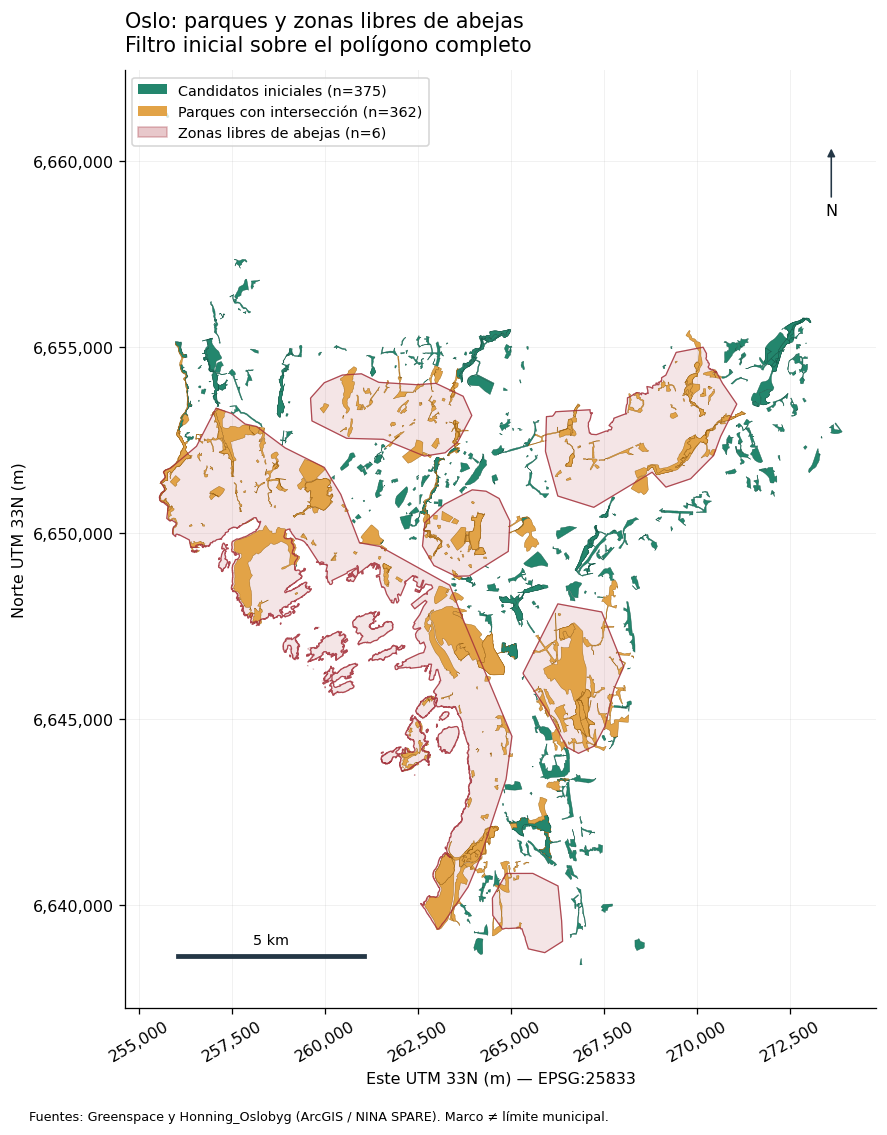

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
zones.plot(ax=ax, facecolor="#B54B53", edgecolor="#A4313B", alpha=.14, linewidth=.7)
candidate = parks.is_initial_candidate
if candidate.any():
    parks.loc[candidate].plot(ax=ax, color="#23866D", edgecolor="#165A4A", linewidth=.25)
if (~candidate).any():
    parks.loc[~candidate].plot(ax=ax, color="#E2A347", edgecolor="#996113", linewidth=.25)
zones.boundary.plot(ax=ax, color="#A4313B", linewidth=.8, alpha=.85)
ax.set_title("Oslo: parques y zonas libres de abejas\nFiltro inicial sobre el polígono completo", loc="left", pad=12)
ax.set_xlabel("Este UTM 33N (m) — EPSG:25833")
ax.set_ylabel("Norte UTM 33N (m)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:,.0f}"))
ax.tick_params(axis="x", rotation=30)
ax.grid(alpha=.18, linewidth=.6)
ax.set_axisbelow(True)
ax.set_aspect("equal")
ax.legend(handles=[Patch(facecolor="#23866D", label=f"Candidatos iniciales (n={int(candidate.sum())})"),
                   Patch(facecolor="#E2A347", label=f"Parques con intersección (n={int((~candidate).sum())})"),
                   Patch(facecolor="#B54B53", edgecolor="#A4313B", alpha=.3, label=f"Zonas libres de abejas (n={len(zones)})")],
          loc="upper left", fontsize=9)
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
bar_length = 5000  # 5 km reales en el CRS métrico, no un parámetro del modelo.
x0, y0 = xmin + .07 * (xmax - xmin), ymin + .055 * (ymax - ymin)
ax.plot([x0, x0 + bar_length], [y0, y0], color="#243746", lw=3)
ax.text(x0 + bar_length / 2, y0 + .012 * (ymax - ymin), "5 km", ha="center", fontsize=9)
ax.annotate("N", xy=(.94, .92), xytext=(.94, .85), xycoords="axes fraction",
            ha="center", va="center", arrowprops={"arrowstyle": "-|>", "color": "#243746"})
fig.text(.1, .02, "Fuentes: Greenspace y Honning_Oslobyg (ArcGIS / NINA SPARE). Marco ≠ límite municipal.", fontsize=8)
fig.tight_layout(rect=(0, .035, 1, 1))
plt.show()

## 9. Inspección del servicio de aptitud para polinizadores
Se conserva una instantánea verificable del documento REST del MapServer y de las respuestas de la subcapa y su consulta. Las dos últimas son diagnósticas: una operación no disponible se registra sin impedir el paisaje vectorial. Una falla de red diagnóstica se distingue de una operación rechazada y no demuestra ausencia de datos.

`Map,TilesOnly`, teselas PNG y `exportTilesAllowed=False` describen acceso cartográfico mediante caché; una tesela es una imagen, no un raster analítico con valores y unidades. Tampoco el hecho de poder ver o solicitar PNG prueba acceso al raster original. Las conclusiones se limitan al **endpoint suministrado**; no se afirma que el autor no disponga de datos en otra ubicación.

In [8]:
def optional_probe(url, params):
    try:
        response = session.get(url, params=params, timeout=(10, 30))
        try:
            payload = response.json()
        except ValueError:
            payload = {"non_json_content_type": response.headers.get("Content-Type")}
        return {"url": url, "params": params, "http_status": response.status_code, "response": payload}
    except requests.RequestException as exc:
        return {"url": url, "params": params, "network_error": str(exc)}

suitability_path = RAW / "pollinator_suitability_inspection.json"
if not REFRESH_SOURCES and suitability_path.exists():
    suitability_snapshot = json.loads(suitability_path.read_text(encoding="utf-8"))
    if suitability_snapshot["source_url"] != SUITABILITY_URL:
        raise RuntimeError("URL de aptitud no coincide con la fuente solicitada.")
    if hashlib.sha256(json_bytes(suitability_snapshot["inspection"])).hexdigest() != suitability_snapshot["sha256"]:
        raise RuntimeError("Huella de la inspección de aptitud incorrecta.")
    print("Aptitud: inspección local verificada de", suitability_snapshot["retrieved_at_utc"])
else:
    inspection = {"service": request_json(SUITABILITY_URL),
                  "layer_probe": optional_probe(SUITABILITY_URL + "/0", {"f": "json"}),
                  "query_probe": optional_probe(SUITABILITY_URL + "/0/query",
                                                {"f": "json", "where": "1=1", "returnCountOnly": "true"})}
    suitability_snapshot = {"source_url": SUITABILITY_URL, "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                            "inspection": inspection, "sha256": hashlib.sha256(json_bytes(inspection)).hexdigest()}
    write_atomic(suitability_path, json_bytes(suitability_snapshot))
suitability = suitability_snapshot["inspection"]["service"]
extent = suitability.get("fullExtent", {})
sr = suitability.get("spatialReference", {})
wkid = sr.get("latestWkid", sr.get("wkid"))
display(pd.DataFrame([{
    "tipo": suitability.get("type"), "capacidades": suitability.get("capabilities"),
    "CRS": sr, "extensión completa": extent,
    "caché única": suitability.get("singleFusedMapCache"),
    "formato de tesela": suitability.get("tileInfo", {}).get("format"),
    "exportTilesAllowed": suitability.get("exportTilesAllowed"),
    "capas": suitability.get("layers"), "fecha inspección UTC": suitability_snapshot["retrieved_at_utc"]}]))
if wkid and all(k in extent for k in ["xmin", "ymin", "xmax", "ymax"]):
    suitability_crs = CRS.from_epsg(wkid)
    from pyproj import Transformer
    transformer = Transformer.from_crs(suitability_crs, 4326, always_xy=True)
    print("Extensión nativa [xmin, ymin, xmax, ymax]:", [extent[k] for k in ["xmin", "ymin", "xmax", "ymax"]])
    print("Envolvente geográfica de esa extensión (no geometría administrativa):",
          transformer.transform_bounds(extent["xmin"], extent["ymin"], extent["xmax"], extent["ymax"]))
for key in ["layer_probe", "query_probe"]:
    print(key)
    display(suitability_snapshot["inspection"][key])
caps = {x.strip().lower() for x in suitability.get("capabilities", "").split(",")}
if "tilesonly" in caps:
    print("Conclusión: servicio de visualización por teselas; no declara consulta de valores numéricos de aptitud.")
else:
    print("Las capacidades cambiaron: revisar manualmente acceso numérico y semántica antes de usar aptitud.")
print("No se descargó un raster numérico ni se asignó aptitud a los parques.")

,tipo,capacidades,CRS,extensión completa,caché única,formato de tesela,exportTilesAllowed,capas,fecha inspección UTC
0,MapServer,"Map,TilesOnly","{'wkid': 102100, 'latestWkid': 3857}","{'xmin': 1161166.602895897, 'ymin': 8364907.861392822, 'xmax': 1239717.181434682, 'ymax': 839962...",True,PNG,False,"[{'id': 0, 'name': 'Egnethet for pollinerende insekter', 'parentLayerId': -1, 'defaultVisibility...",2026-10-31T00:52:19.989112+00:00


Extensión nativa [xmin, ymin, xmax, ymax]: [1161166.602895897, 8364907.861392822, 1239717.181434682, 8399620.894157777]
Envolvente geográfica de esa extensión (no geometría administrativa): (10.430937067905273, 59.84318795266275, 11.136568920683487, 59.99947450087567)
layer_probe


{'url': 'https://tiles.arcgis.com/tiles/PHc9pAOcTcVH6T4R/arcgis/rest/services/Egnethet_for_pollinerende_insekter/MapServer/0',
 'params': {'f': 'json'},
 'http_status': 200,
 'response': {'currentVersion': 10.81,
  'id': 0,
  'name': 'Egnethet for pollinerende insekter',
  'type': 'Raster Layer',
  'description': '',
  'geometryType': None,
  'copyrightText': '',
  'parentLayer': None,
  'subLayers': [],
  'minScale': 0,
  'maxScale': 0,
  'defaultVisibility': True,
  'extent': {'xmin': 1181209.476718691,
   'ymin': 8357127.14380127,
   'xmax': 1219332.7886323573,
   'ymax': 8397191.165154535,
   'spatialReference': {'wkid': 102100, 'latestWkid': 3857}},
  'hasAttachments': False,
  'htmlPopupType': 'esriServerHTMLPopupTypeNone',
  'displayField': '',
  'typeIdField': None,
  'subtypeFieldName': None,
  'subtypeField': None,
  'defaultSubtypeCode': None,
  'fields': None,
  'geometryField': {},
  'indexes': [],
  'subtypes': [],
  'relationships': [],
  'canModifyLayer': False,
  'canS

query_probe


{'url': 'https://tiles.arcgis.com/tiles/PHc9pAOcTcVH6T4R/arcgis/rest/services/Egnethet_for_pollinerende_insekter/MapServer/0/query',
 'params': {'f': 'json', 'where': '1=1', 'returnCountOnly': 'true'},
 'http_status': 404,
 'response': {'non_json_content_type': 'text/html;charset=iso-8859-1'}}

Conclusión: servicio de visualización por teselas; no declara consulta de valores numéricos de aptitud.
No se descargó un raster numérico ni se asignó aptitud a los parques.


## 10. Exportación y comprobación de resultados
Se guardan los tres productos solicitados. El análisis permanece en EPSG:25833. Para interoperabilidad los **GeoJSON se exportan en EPSG:4326, siguiendo RFC 7946**; sus atributos `area_m2`, `centroid_x_m`, `centroid_y_m` y `centroid_wkt` conservan unidades y CRS analíticos, señalados con `analysis_crs`. Para calcular nuevas distancias o áreas hay que cargar y reproyectar otra vez a EPSG:25833.

`spatial_patches.csv` contiene centroides métricos, identificadores, intersección, área solapada y candidatura. No contiene una segunda columna de geometría activa ni variables ecológicas inventadas. Se comprueban lectura de vuelta, IDs, conteos, áreas y clasificación espacial. Las exportaciones son deterministas para una misma instantánea y entorno.

In [9]:
parks_path = OUT / "oslo_parks.geojson"
zones_path = OUT / "bee_free_zones.geojson"
patches_path = OUT / "spatial_patches.csv"
write_atomic(parks_path, parks.to_crs(4326).to_json(drop_id=True, to_wgs84=True).encode("utf-8"))
write_atomic(zones_path, zones.to_crs(4326).to_json(drop_id=True, to_wgs84=True).encode("utf-8"))
write_atomic(patches_path, spatial_patches.to_csv(index=False, lineterminator="\n").encode("utf-8"))

parks_check = gpd.read_file(parks_path).to_crs(METRIC_CRS)
zones_check = gpd.read_file(zones_path).to_crs(METRIC_CRS)
csv_check = pd.read_csv(patches_path)
assert len(parks_check) == parks_manifest["count"] == len(csv_check)
assert len(zones_check) == zones_manifest["count"]
assert parks_check.patch_id.is_unique and csv_check.patch_id.is_unique
assert parks_check.patch_id.tolist() == csv_check.patch_id.tolist()
assert parks_check.geometry.is_valid.all() and zones_check.geometry.is_valid.all()
assert (parks_check.geometry.area.sub(parks_check.area_m2).abs() <= parks_check.area_m2 * 1e-7 + .01).all()
assert parks_check.geometry.intersects(unary_union(zones_check.geometry)).tolist() == parks.intersects_restricted_zone.tolist()
assert csv_check.is_initial_candidate.tolist() == parks.is_initial_candidate.tolist()
assert csv_check.intersects_restricted_zone.tolist() == parks.intersects_restricted_zone.tolist()
display(pd.DataFrame([{"archivo": str(p.relative_to(ROOT)), "bytes": p.stat().st_size,
                       "SHA-256": hashlib.sha256(p.read_bytes()).hexdigest()}
                      for p in [parks_path, zones_path, patches_path]]))
print("Exportaciones releídas y verificadas correctamente.")

,archivo,bytes,SHA-256
0,data\project2\processed\oslo_parks.geojson,5547696,b1e37b09373c5b0e0cfca4c44ea7f8263c00d52648310e80c59dca560e9bd33d
1,data\project2\processed\bee_free_zones.geojson,2994432,1e020dbd81b2864bd4059466dfe2ea47e5bab5c4ec1f52a000992bdb062379b5
2,data\project2\processed\spatial_patches.csv,294268,2145b59ed04aeee9e4611a7e81b6cf5afd6d94f757180af9490e0a378d45e757


Exportaciones releídas y verificadas correctamente.


## Conclusiones para el modelo espacial
**Geometrías reales disponibles:** polígonos originales de parques/áreas verdes y zonas libres de abejas, con atributos, identificadores de fuente y trazabilidad. Las áreas y centroides se calcularon en un CRS métrico. Las cifras siguientes provienen de esta instantánea, no de valores escritos manualmente.

In [10]:
print(f"• Parques/áreas verdes: {len(parks):,}; zonas libres de abejas: {len(zones):,}.")
print(f"• Parques que intersectan una zona: {int(parks.intersects_restricted_zone.sum()):,}.")
print(f"• Candidatos iniciales con la regla conservadora: {int(parks.is_initial_candidate.sum()):,}.")
print(f"• Geometrías reparadas: parques {int(parks.geometry_repaired.sum())}; zonas {int(zones.geometry_repaired.sum())}.")
print(f"• Área de la unión de parques: {unary_union(parks.geometry).area / 1e6:.3f} km².")
print(f"• Centroides fuera del parque: {int((~parks.centroid_inside_patch).sum())}; no son ubicaciones de colmenas.")
print("• Aptitud: capacidades declaradas", suitability.get("capabilities"), "; no se asignaron valores numéricos.")

• Parques/áreas verdes: 737; zonas libres de abejas: 6.
• Parques que intersectan una zona: 362.
• Candidatos iniciales con la regla conservadora: 375.
• Geometrías reparadas: parques 11; zonas 0.


• Área de la unión de parques: 23.562 km².
• Centroides fuera del parque: 165; no son ubicaciones de colmenas.
• Aptitud: capacidades declaradas Map,TilesOnly ; no se asignaron valores numéricos.


**Restricciones que ya pueden aplicarse:** intersección espacial con la capa real de zonas libres de abejas. La primera versión excluye de candidatura cualquier polígono que la toque o cruce. Esta regla es deliberadamente conservadora; no elimina parques del paisaje ni demuestra prohibición legal vigente para cada fecha. Antes de ubicar colmenas deben validarse alcance, vigencia y significado de la restricción.

**Información pendiente:** límites administrativos oficiales si se requieren, interpretación completa de categorías de área verde, permisos y accesibilidad, estabilidad de IDs entre republicaciones, raster numérico y escala de aptitud, y enlace espacial validado con Dryad (sin coordenadas de traps). No se incorporaron otras capas de áreas protegidas ni se las confundió con restricciones apícolas. Faltan además fenología, dinámica temporal y parámetros ecológicos de flores, polen, néctar, agotamiento y competencia; las versiones de estas capas GIS no acreditan correspondencia con la campaña ecológica de 2017.

**Salidas para `03_temporal_model.ipynb`:** `oslo_parks.geojson` aporta huellas espaciales, áreas y banderas; `bee_free_zones.geojson` permite reevaluar restricciones; `spatial_patches.csv` deja un catálogo de parches con IDs, centroides métricos y candidatura inicial. El notebook temporal podrá cargar estas salidas, verificar `patch_id` y agregar exclusivamente variables temporales justificadas en esa fase. Las instantáneas REST permiten repetir el mismo paisaje y distinguir cambios reales de fuente de cambios de código. No se ha modificado ni ejecutado ningún notebook posterior.